Cell 1 — Markdown

# Oasis Infobyte Data Science Internship
## Task 1: Iris Flower Classification

**Objective:** Predict Iris flower species using flower measurements.

**Dataset:** Iris dataset from Scikit-learn

**Algorithms:**
1. Logistic Regression
2. K-Nearest Neighbors (KNN)

**Evaluation Metrics:** Accuracy, Confusion Matrix, Precision, Recall, and F1-score.

Cell 2 — Code: Import libraries

In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import Iris dataset
from sklearn.datasets import load_iris

# Import data splitting and preprocessing tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Import classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    f1_score
)

# Set visualization style
sns.set_theme(style="whitegrid")

# Display plots inside the notebook
%matplotlib inline

Cell 3 — Markdown

## 1. Load the Iris Dataset

The Iris dataset contains 150 samples from three species:
Setosa, Versicolor, and Virginica.

Each sample has four numerical features:
- Sepal length
- Sepal width
- Petal length
- Petal width

The dataset is loaded directly from Scikit-learn without downloading any files.

Cell 4 — Code: Load dataset

In [2]:
# Load the built-in Iris dataset
iris = load_iris()

# Create a DataFrame with the four input features
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add the numerical target labels
df["target"] = iris.target

# Add readable species names
df["species"] = pd.Categorical.from_codes(
    iris.target,
    iris.target_names
)

# Display the first five rows
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


Cell 5 — Markdown

## 2. Exploratory Data Analysis (EDA)

EDA helps us understand the dataset's structure, data types, missing values, and statistical properties.

Cell 6 — Code: Shape and data types

In [3]:
# Display dataset dimensions
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display column data types
print("\nColumn Data Types:")
print(df.dtypes)

# Display the number of samples in each species
print("\nSpecies Distribution:")
print(df["species"].value_counts())

Dataset Shape: (150, 6)

Column Names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'target', 'species']

Column Data Types:
sepal length (cm)     float64
sepal width (cm)      float64
petal length (cm)     float64
petal width (cm)      float64
target                  int64
species              category
dtype: object

Species Distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


Cell 7 — Code: Missing values

In [4]:
# Count missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Check whether the dataset contains any missing values
print("\nContains Missing Values:", df.isnull().values.any())

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64

Contains Missing Values: False


Cell 8 — Code: Descriptive statistics

In [5]:
# Display descriptive statistics
print("Descriptive Statistics:")
display(df.describe())

# Display average measurements for each species
print("\nAverage Measurements by Species:")
display(
    df.groupby("species", observed=True)[iris.feature_names].mean()
)

Descriptive Statistics:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000



Average Measurements by Species:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
species,,,,
setosa,5.006,3.428,1.462,0.246
versicolor,5.936,2.770,4.260,1.326
virginica,6.588,2.974,5.552,2.026


Cell 9 — Markdown

## 3. Data Visualization

We use a pairplot to explore relationships between features and box plots to compare the distribution of each feature across species.

Cell 10 — Code: Pairplot

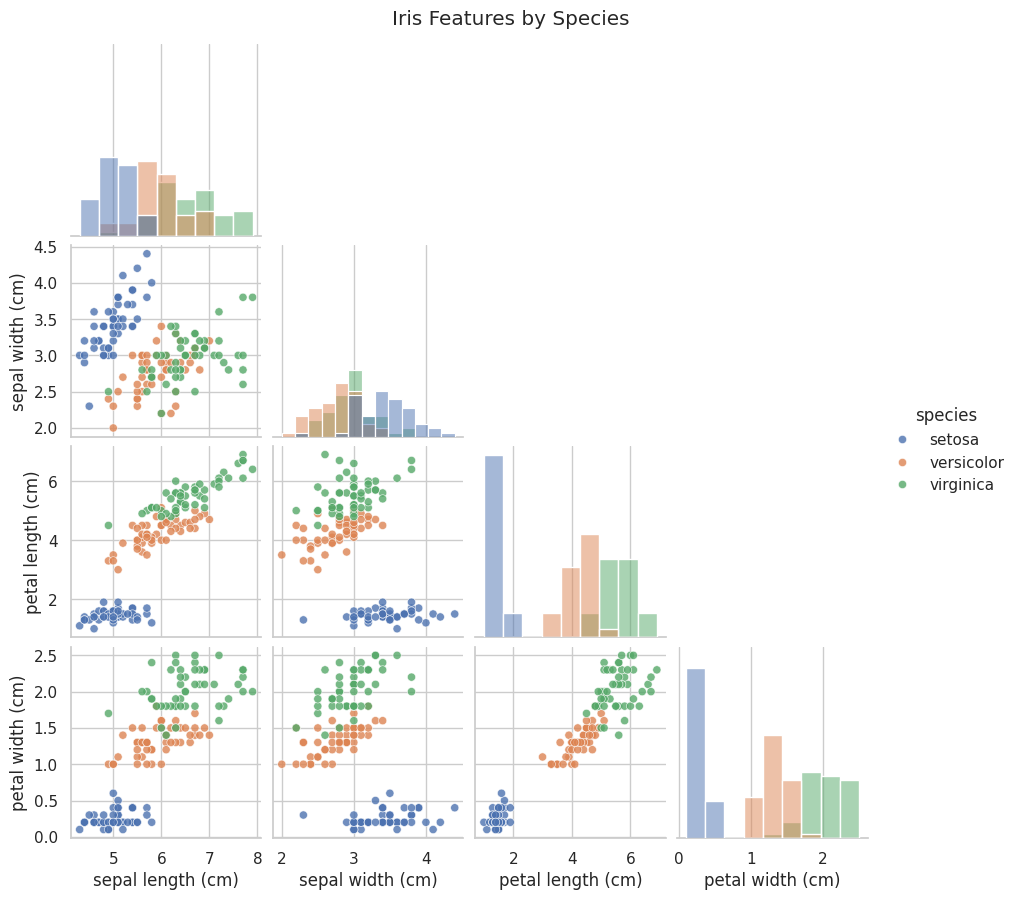

In [6]:
# Select numerical features and species labels
feature_df = df[iris.feature_names + ["species"]]

# Create a pairplot showing relationships between features
pair_plot = sns.pairplot(
    feature_df,
    hue="species",
    diag_kind="hist",
    corner=True,
    height=2.2,
    plot_kws={"alpha": 0.8, "s": 35}
)

# Add a title
pair_plot.figure.suptitle(
    "Iris Features by Species",
    y=1.02
)

# Display the plot
plt.show()

Cell 11 — Code: Box plots

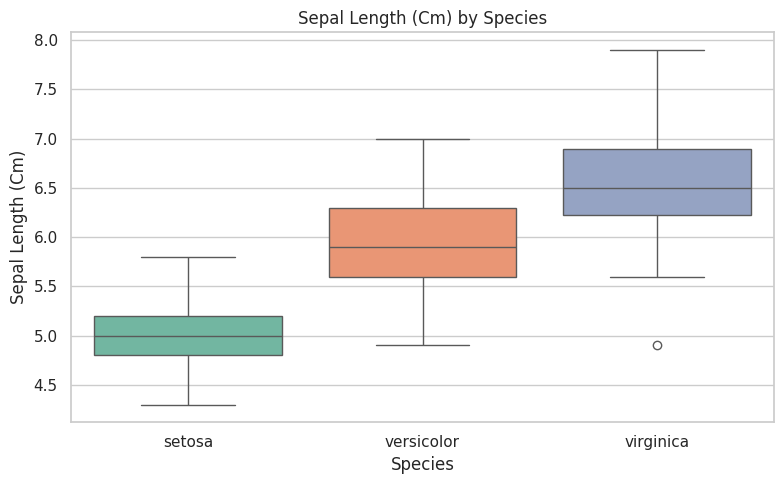

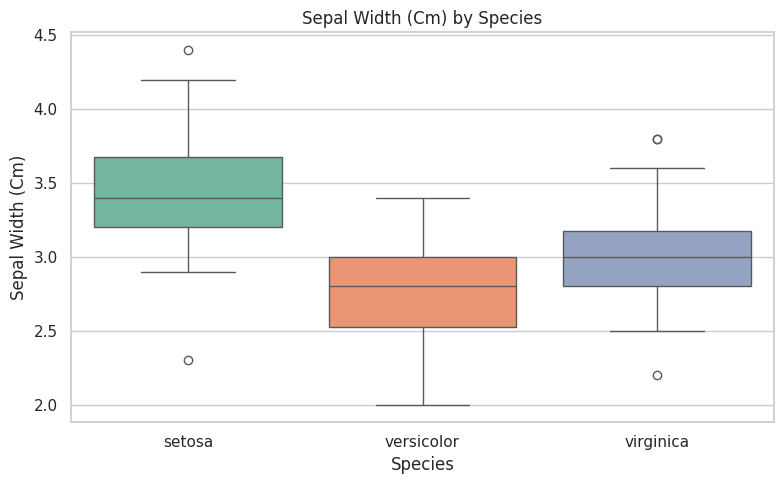

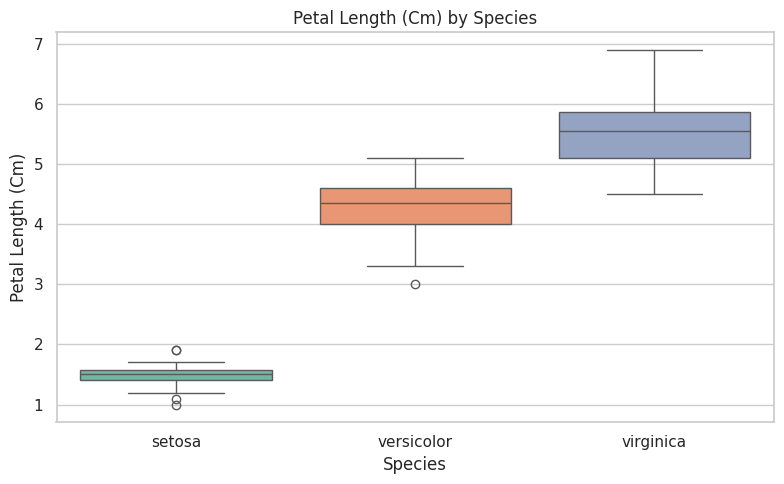

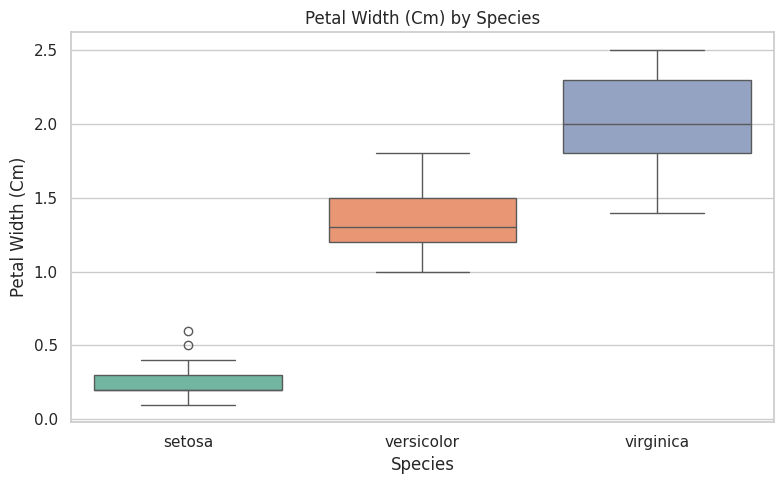

In [7]:
# Create a box plot for each feature
for feature in iris.feature_names:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x="species",
        y=feature,
        hue="species",
        palette="Set2",
        legend=False
    )

    # Add title and axis labels
    plt.title(f"{feature.title()} by Species")
    plt.xlabel("Species")
    plt.ylabel(feature.title())

    # Adjust layout and display the plot
    plt.tight_layout()
    plt.show()

Cell 12 — Markdown: Feature observations

## 4. Most Discriminative Features

Petal length and petal width are generally the most discriminative features for Iris species classification.

- Setosa has distinctly smaller petals than the other species.
- Versicolor and Virginica have larger petals, although their measurements overlap.
- Sepal length provides some separation between species.
- Sepal width is generally less discriminative because the distributions overlap more.

Therefore, petal measurements are expected to be particularly useful for predicting Iris species.

Cell 13 — Markdown

## 5. Split the Dataset

We split the data into 80% training data and 20% testing data.

The training data is used to train the models, while the testing data evaluates their performance on unseen samples.

Cell 14 — Code: Train-test split

In [8]:
# Select the four input features
X = df[iris.feature_names]

# Select the target labels
y = df["target"]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the shapes of the resulting datasets
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (120, 4)
Testing Features: (30, 4)
Training Target: (120,)
Testing Target: (30,)


Cell 15 — Markdown

### Feature Scaling

Feature scaling is important for KNN because it uses distances between samples.

We fit the scaler only on training data to avoid data leakage.

Cell 16 — Code: Standardization

In [9]:
# Create the StandardScaler
scaler = StandardScaler()

# Fit the scaler on training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

# Display the scaled data dimensions
print("Scaled Training Data:", X_train_scaled.shape)
print("Scaled Testing Data:", X_test_scaled.shape)

Scaled Training Data: (120, 4)
Scaled Testing Data: (30, 4)


Cell 17 — Markdown

## 6. Model 1: Logistic Regression

Logistic Regression is a supervised classification algorithm used to predict the probability of a sample belonging to a class.

It can classify Iris flowers into Setosa, Versicolor, or Virginica.

Cell 18 — Code: Train Logistic Regression

In [10]:
# Create the Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
logistic_model.fit(X_train_scaled, y_train)

# Predict species for the testing data
logistic_predictions = logistic_model.predict(X_test_scaled)

# Display actual and predicted labels
print("Actual Labels:", y_test.to_numpy()[:10])
print("Predicted Labels:", logistic_predictions[:10])

Actual Labels: [0 2 1 1 0 1 0 0 2 1]
Predicted Labels: [0 2 1 1 0 1 0 0 2 1]


Cell 19 — Markdown

### Evaluate Logistic Regression

We evaluate the model using accuracy, a confusion matrix, and a classification report containing precision, recall, and F1-score.

Cell 20 — Code: Logistic Regression evaluation

In [11]:
# Calculate accuracy
logistic_accuracy = accuracy_score(
    y_test,
    logistic_predictions
)

print("Logistic Regression Accuracy:", round(logistic_accuracy, 4))

# Calculate the confusion matrix
logistic_cm = confusion_matrix(
    y_test,
    logistic_predictions
)

print("\nConfusion Matrix:")
print(logistic_cm)

# Display the classification report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        logistic_predictions,
        target_names=iris.target_names,
        zero_division=0
    )
)

Logistic Regression Accuracy: 0.9333

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



Cell 21 — Code: Logistic Regression confusion matrix plot

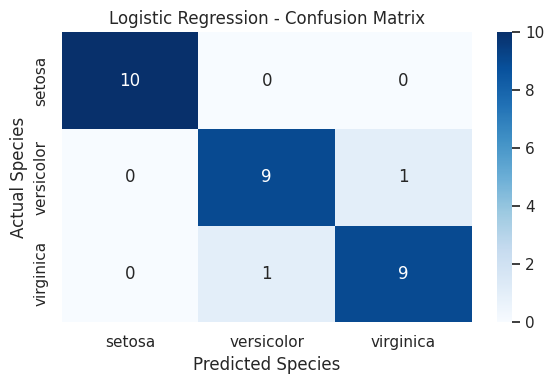

In [12]:
# Plot the confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    logistic_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")

plt.tight_layout()
plt.show()

Cell 22 — Markdown

## 7. Model 2: K-Nearest Neighbors (KNN)

KNN classifies a sample based on the majority class among its nearest training samples.

We use five neighbors and scaled features to train the model.

Cell 23 — Code: Train KNN

In [13]:
# Create the KNN classifier with five neighbors
knn_model = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn_model.fit(X_train_scaled, y_train)

# Predict species for the testing data
knn_predictions = knn_model.predict(X_test_scaled)

# Display actual and predicted labels
print("Actual Labels:", y_test.to_numpy()[:10])
print("Predicted Labels:", knn_predictions[:10])

Actual Labels: [0 2 1 1 0 1 0 0 2 1]
Predicted Labels: [0 2 1 1 0 1 0 0 2 1]


Cell 24 — Markdown

### Evaluate K-Nearest Neighbors

We evaluate KNN using the same metrics and testing data used for Logistic Regression.

Cell 25 — Code: KNN evaluation

In [14]:
# Calculate KNN accuracy
knn_accuracy = accuracy_score(
    y_test,
    knn_predictions
)

print("KNN Accuracy:", round(knn_accuracy, 4))

# Calculate the confusion matrix
knn_cm = confusion_matrix(
    y_test,
    knn_predictions
)

print("\nConfusion Matrix:")
print(knn_cm)

# Display the classification report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        knn_predictions,
        target_names=iris.target_names,
        zero_division=0
    )
)

KNN Accuracy: 0.9333

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



Cell 26 — Code: KNN confusion matrix plot

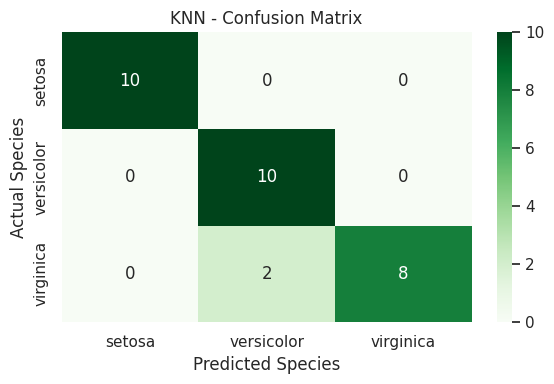

In [15]:
# Plot the KNN confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    knn_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("KNN - Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")

plt.tight_layout()
plt.show()

Cell 27 — Markdown

## 8. Compare the Models

We compare both models using their test accuracy scores and macro-average F1-scores.

Cell 28 — Code: Comparison table

In [16]:
# Create a table comparing both models
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "K-Nearest Neighbors"
    ],
    "Accuracy": [
        logistic_accuracy,
        knn_accuracy
    ]
})

# Sort models by accuracy
model_comparison = model_comparison.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

# Display the comparison table
display(model_comparison)

,Model,Accuracy
0,Logistic Regression,0.933333
1,K-Nearest Neighbors,0.933333


Cell 29 — Code: Select the best model

In [17]:
# Calculate macro-average F1-scores
logistic_macro_f1 = f1_score(
    y_test,
    logistic_predictions,
    average="macro"
)

knn_macro_f1 = f1_score(
    y_test,
    knn_predictions,
    average="macro"
)

# Compare accuracy first, then macro F1-score
if logistic_accuracy > knn_accuracy:
    best_model_name = "Logistic Regression"

elif knn_accuracy > logistic_accuracy:
    best_model_name = "K-Nearest Neighbors"

elif logistic_macro_f1 > knn_macro_f1:
    best_model_name = "Logistic Regression"

elif knn_macro_f1 > logistic_macro_f1:
    best_model_name = "K-Nearest Neighbors"

else:
    best_model_name = "Tie"

# Display evaluation results
print("Logistic Regression Accuracy:", round(logistic_accuracy, 4))
print("Logistic Regression Macro F1:", round(logistic_macro_f1, 4))

print("\nKNN Accuracy:", round(knn_accuracy, 4))
print("KNN Macro F1:", round(knn_macro_f1, 4))

print("\nBest-Performing Model:", best_model_name)

Logistic Regression Accuracy: 0.9333
Logistic Regression Macro F1: 0.9333

KNN Accuracy: 0.9333
KNN Macro F1: 0.9327

Best-Performing Model: Logistic Regression


Cell 30 — Markdown: Best model justification

## 9. Best-Performing Model and Justification

The best-performing model is identified from the test-set results.

- Higher accuracy indicates that a larger proportion of test samples were classified correctly.
- Macro F1-score compares precision and recall while giving equal weight to all three species.
- The confusion matrix and classification report provide additional information about misclassifications.

If both accuracy and macro F1-score are equal, neither model is a clear winner based on these metrics.

The conclusion applies to this particular train-test split. Cross-validation could provide a more robust comparison.

Cell 31 — Markdown: Conclusion

10. Conclusion

In this project, the Iris dataset was analyzed using Exploratory Data Analysis (EDA) and data visualization. Two machine learning algorithms, Logistic Regression and K-Nearest Neighbors (KNN), were trained and evaluated.

Both models achieved **93.33% accuracy** on the test dataset. However, Logistic Regression achieved a slightly higher macro F1-score of **0.9333**, compared with **0.9327** for KNN.

Therefore, Logistic Regression is the best-performing model for this experiment based on the evaluation results. The visualizations also indicated that petal length and petal width are important features for distinguishing Iris flower species.

This project demonstrates the machine learning workflow, including data preprocessing, visualization, model training, and performance evaluation.